# Wall slip, parallel channels and apparent flow thresholds

Suppose you push a paste through a tube and record the pressure gradient at which it starts to move. Is that the yield stress of the paste? Not necessarily. Many yield-stress materials — microgel pastes, emulsions, foams, concentrated suspensions — **slip** along smooth walls, so the whole sample can slide as a rigid plug at a wall stress well below the bulk yield stress. And when the material flows through many paths at once, as in a porous rock or a filter, each path opens at its own pressure, so the threshold you see is set by the widest path and the flow rate rises gradually rather than abruptly. This notebook builds both effects on top of the exact Herschel–Bulkley (HB) pipe solution, reproduces Fig. 10 of the review, and explains why an observed flow threshold is not automatically a bulk yield stress.

## Where this is in the review

* **Sec. VII D** *Wall slip and apparent thresholds* — flow rate with slip, **Eq. (26)**; threshold slip law, **Eq. (27)**; rigid sliding for $\sigma_s<\sigma_w<\sigma_y$; parallel capillaries; multi-radius slip separation.
* **Fig. 10** — (a) pipe flow with slip, (b) a bundle of five independent capillaries. Script `scripts/fig10_slip_network.py`; plotted values `data/figure_data/fig10_slip_network.csv`.
* **Sec. VI C** *Wall slip and confinement* — measured slip laws (Meeker, Bonnecaze and Cloitre, 2004; Seth, Cloitre and Bonnecaze, 2008; reviewed by Cloitre and Bonnecaze, 2017), the Mooney analysis and its failure modes, velocimetry as the reference practice.
* **Sec. VII A–C** — the no-slip pipe solution, Eqs. (19) and (23), and the onset condition, Eq. (22) (see notebook 05).
* **Sec. VII B** — a threshold in imposed force is not a threshold in imposed velocity; **Sec. VI A** — operational definitions of the yield stress.
* **Sec. IX G** — progressive recruitment of flow paths in porous media.
* **Supplementary Note S9 E** — pressure-work identity with the slip term $2\pi R\sigma_w u_s$; **Note S7 A**, Table SIV — the whole-plug sliding exponent $Q\propto(\sigma_w-\sigma_s)^{p_s}$.

## Learning objectives

1. Write the flow rate of an HB fluid in a pipe with a wall-slip law and identify the three regimes (rest, rigid sliding, sliding plus bulk shear).
2. Reproduce Fig. 10(a) and see how a sliding threshold $\sigma_s<\sigma_y$ produces flow below the bulk yield stress.
3. Show that fitting a no-slip HB law to such data returns apparent parameters.
4. Separate slip from bulk flow with several radii (Mooney/Kalyon), and see how noise is amplified.
5. Reproduce Fig. 10(b) and explain the gradual activation of a bundle of capillaries.
6. List the tests that distinguish a bulk yield stress from a sliding or geometric threshold.

## 1. Theory

### 1.1 Pipe flow with wall slip

Momentum balance does not care about the wall condition: in fully developed pipe flow the shear stress is still $\sigma(r)=Gr/2$ and $\sigma_w=GR/2$. If the material slides along the wall with a velocity $u_s(\sigma_w)$ and the bulk follows the HB law, the velocity profile is the no-slip profile shifted by $u_s$, and the flow rate is (Eq. (26))

$$
Q(G)=Q_{\rm HB,no\text{-}slip}(G)+\pi R^2u_s(\sigma_w),
$$

with $Q_{\rm HB,no\text{-}slip}$ given by Eq. (19) or Eq. (23). A simple dissipative threshold law for the slip velocity is (Eq. (27))

$$
u_s=B_s\,(\sigma_w-\sigma_s)_+^{p_s},\qquad B_s>0,\; p_s>0,
$$

where $(x)_+=\max(x,0)$ and $\sigma_s$ is a **wall sliding threshold**, distinct from the bulk yield stress $\sigma_y$. Power-law slip with a small or vanishing $\sigma_s$ is observed for soft pastes on smooth walls (Sec. VI C).

### 1.2 Three regimes when $\sigma_s<\sigma_y$

* $\sigma_w\le\sigma_s$: nothing moves.
* $\sigma_s<\sigma_w<\sigma_y$: the stress is below yield everywhere, so the bulk is rigid — but the wall stress exceeds the sliding threshold, so the **whole cross-section translates as a rigid plug** at speed $u_s$. Flow starts at $G_s=2\sigma_s/R$ rather than at $G_c=2\sigma_y/R$.
* $\sigma_w>\sigma_y$: an annulus near the wall shears and the plug shrinks to $r_p=R\sigma_y/\sigma_w$, while the wall sliding continues.

If instead $\sigma_s>\sigma_y$, bulk shear begins first and sliding is added above $\sigma_s$. Either way, the stress at which flow is first seen is $\min(\sigma_s,\sigma_y)$: **an observed flow threshold is not automatically a bulk yield stress** (Chaparian and Tammisola, 2021).

### 1.3 Dimensionless form used in Fig. 10(a)

With the mean velocity $U=Q/(\pi R^2)$ and the velocity scale $R(\sigma_y/K)^{1/n}$,

$$
\frac{U}{R(\sigma_y/K)^{1/n}}=\frac{Q_{\rm HB,no\text{-}slip}}{\pi R^3(\sigma_y/K)^{1/n}}+\tilde B_s\left(\frac{\sigma_w}{\sigma_y}-\frac{\sigma_s}{\sigma_y}\right)_+^{p_s},
\qquad \tilde B_s=\frac{B_s\sigma_y^{p_s}}{R(\sigma_y/K)^{1/n}} .
$$

Fig. 10(a) uses $n=0.5$, $\sigma_s=0.4\sigma_y$ and $p_s=1$ (caption); the dimensionless slip coefficient used in the figure script is $\tilde B_s=0.3$.

### 1.4 Separating slip and bulk flow with several radii

Dividing Eq. (26) by $\pi R^3$ at **fixed wall stress**,

$$
\frac{Q}{\pi R^3}=\underbrace{\frac{Q_{\rm HB,no\text{-}slip}}{\pi R^3}}_{\text{independent of }R}+\frac{u_s(\sigma_w)}{R}.
$$

Plotting $Q/(\pi R^3)$ against $1/R$ for tubes of several radii at the same $\sigma_w$ gives a straight line whose slope is $u_s$. This is the basis of the Mooney (1931) analysis, of its parallel-plate analogue (Yoshimura and Prud'homme, 1988) and of multi-radius slip separation (Kalyon, 2005). It requires comparable samples, surfaces, entrance corrections and material state, and it assumes that $u_s$ depends only on $\sigma_w$ (Secs. VI C and VII D).

### 1.5 A bundle of independent capillaries

For $N$ capillaries of radii $R_i$ connected in parallel between the same two pressures, every channel feels the same gradient $G$ but its own wall stress $GR_i/2$. Channel $i$ opens at $G_{c,i}=2\sigma_y/R_i$, so the widest opens first and the total

$$
Q_{\rm tot}(G)=\sum_{i=1}^{N}Q_{\rm HB,no\text{-}slip}(GR_i/2;\,R_i)
$$

rises gradually as narrower channels are recruited. Fig. 10(b) uses five channels with $R/R_{\max}=1,\,0.8,\,0.65,\,0.5,\,0.35$ and $n=0.5$. The bundle is a picture used in capillary models of porous media (Al-Fariss and Pinder, 1987; Oukhlef, Ambari and Champmartin, 2020), not a calibrated porous-medium model.

## 2. Setup

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Locate the repository root whether the notebook is run from notebooks/ or from the root.
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if (ROOT.parent / "data").exists() and not (ROOT / "data").exists() else ROOT
sys.path.insert(0, str(ROOT / "scripts"))
sys.dont_write_bytecode = True      # do not write __pycache__ files into scripts/

from hbstyle import C   # the article's colour palette and plot style (we never call hbstyle.save)
plt.rcParams["figure.dpi"] = 110
print("data folder found:", (ROOT / "data").is_dir())

from scipy.optimize import least_squares
from verify_equations import pipe_q      # the review's implementation of Eq. (23), used by the figure script

data folder found: True


In [2]:
def q_noslip(tw, ty, K, n, R=1.0):
    """No-slip HB pipe flow rate, Eq. (23) (zero below the yield stress)."""
    if tw <= ty:
        return 0.0
    d = tw - ty
    return np.pi * R**3 / (K ** (1 / n) * tw**3) * (d ** (3 + 1 / n) / (3 + 1 / n)
            + 2 * ty * d ** (2 + 1 / n) / (2 + 1 / n) + ty**2 * d ** (1 + 1 / n) / (1 + 1 / n))

def slip_velocity(tw, Bs, sigma_s, ps):
    """Threshold slip law, Eq. (27)."""
    return Bs * np.clip(np.asarray(tw, float) - sigma_s, 0.0, None) ** ps

# quick consistency check with the review's own function
assert all(np.isclose(q_noslip(t, 1.0, 0.8, n, 0.7), pipe_q(t, 1.0, 0.8, n, 0.7), rtol=1e-12)
           for t in [1.1, 2.0, 5.0] for n in [0.4, 1.0])

## 3. Pipe flow with a sliding threshold — Fig. 10(a)

We work in the units of Fig. 10(a): $\sigma_y=K=R=1$, so stresses are in units of $\sigma_y$ and $U$ in units of $R(\sigma_y/K)^{1/n}$.

In [3]:
n = 0.5
sigma_y, K, R = 1.0, 1.0, 1.0
sigma_s, ps, Bs = 0.4, 1.0, 0.3            # sliding threshold, slip exponent, dimensionless slip coefficient (Fig. 10a)

tw = np.linspace(0, 2.8, 500)                                        # sigma_w / sigma_y
U_bulk = np.array([q_noslip(t, sigma_y, K, n, R) for t in tw]) / (np.pi * R**2)
U_slip = slip_velocity(tw, Bs, sigma_s, ps)
U_tot = U_bulk + U_slip                                              # Eq. (26) divided by pi R^2

for t in [0.3, 0.7, 1.5, 2.5]:
    i = np.argmin(abs(tw - t))
    share = f"{U_slip[i] / U_tot[i]:.2f}" if U_tot[i] > 0 else "- (no flow)"
    print(f"sigma_w/sigma_y = {tw[i]:.2f}: bulk U = {U_bulk[i]:.4f}, sliding U = {U_slip[i]:.4f}, sliding share = {share}")

sigma_w/sigma_y = 0.30: bulk U = 0.0000, sliding U = 0.0000, sliding share = - (no flow)
sigma_w/sigma_y = 0.70: bulk U = 0.0000, sliding U = 0.0904, sliding share = 1.00
sigma_w/sigma_y = 1.50: bulk U = 0.0232, sliding U = 0.3295, sliding share = 0.93
sigma_w/sigma_y = 2.50: bulk U = 0.3325, sliding U = 0.6308, sliding share = 0.65


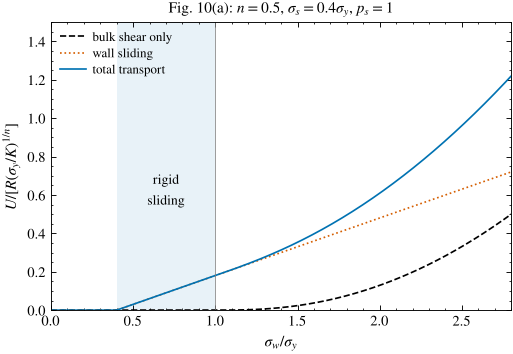

Fig. 10(a): bulk, sliding and total curves, sliding band and yield line agree with data/figure_data/fig10_slip_network.csv (rtol 1e-8).


In [4]:
fd = pd.read_csv(ROOT / "data" / "figure_data" / "fig10_slip_network.csv", comment="#")
def stored(panel, series, kind=None):
    s = fd[(fd.panel == panel) & (fd.series == series)]
    if kind:
        s = s[s.kind == kind]
    return s.sort_values("index")

fig, ax = plt.subplots(figsize=(5.4, 3.4))
ax.plot(tw, U_bulk, color="k", ls="--", label="bulk shear only")
ax.plot(tw, U_slip, color=C["red"], ls=":", label="wall sliding")
ax.plot(tw, U_tot, color=C["blue"], label="total transport")
ax.axvspan(sigma_s, sigma_y, color=C["blue"], alpha=0.09, lw=0)
ax.axvline(sigma_y, color="grey", lw=0.5)
ax.text(0.7, 0.55, "rigid\nsliding", ha="center", fontsize=9)
ax.set(xlabel=r"$\sigma_w/\sigma_y$", ylabel=r"$U/[R(\sigma_y/K)^{1/n}]$", xlim=(0, 2.8), ylim=(0, 1.5))
ax.legend(loc="upper left", fontsize=8.5)
ax.set_title(r"Fig. 10(a): $n=0.5$, $\sigma_s=0.4\sigma_y$, $p_s=1$", fontsize=10)
plt.show()

# Check against the stored figure data (10 significant digits)
for name, y in [("bulk shear only", U_bulk), ("wall sliding", U_slip), ("total transport", U_tot)]:
    s = stored("(a)", name)
    assert np.allclose(s.x.to_numpy(), tw, rtol=1e-8, atol=1e-12) and np.allclose(s.y.to_numpy(), y, rtol=1e-8, atol=1e-12), name
band = stored("(a)", "rigid sliding").iloc[0]
assert np.isclose(band.x, sigma_s) and np.isclose(band.x_end, sigma_y)
assert np.isclose(stored("(a)", "bulk yield, sigma_w = sigma_y").iloc[0].x, sigma_y)
print("Fig. 10(a): bulk, sliding and total curves, sliding band and yield line agree with "
      "data/figure_data/fig10_slip_network.csv (rtol 1e-8).")

Between $\sigma_w=0.4\sigma_y$ and $\sigma_y$ the material moves, yet nothing inside it is yielded: the plug fills the pipe and slides. Above $\sigma_y$ bulk shear adds to the sliding, and its share grows because the bulk term grows roughly as $\sigma_w^{1/n}=\sigma_w^2$ while the sliding term grows linearly; even at $2.5\,\sigma_y$, however, sliding still carries about two-thirds of the transport for these parameters. (The review's figure extends the horizontal axis to 4.75 to make room for curve labels; the data stop at 2.8.)

### 3.1 What a pressure-ramp experiment would report

An experimenter who raises the pressure until flow is detected sees the first motion at $\sigma_w=\sigma_s$, not at $\sigma_y$. Worse, if the data are analyzed with a **no-slip** HB pipe model, the fitted parameters are neither the bulk nor the wall values. *Going beyond the review*, we fit Eq. (23) (no slip) to the total transport curve above a detection limit, with relative residuals.

first detected flow at sigma_w/sigma_y = 0.438  (bulk yield stress = 1, sliding threshold = 0.4)
no-slip HB fit to the data: sigma_y = 0.265, K = 0.793, n = 0.734   (truth: 1, 1, 0.5); rms relative misfit = 7.9 %


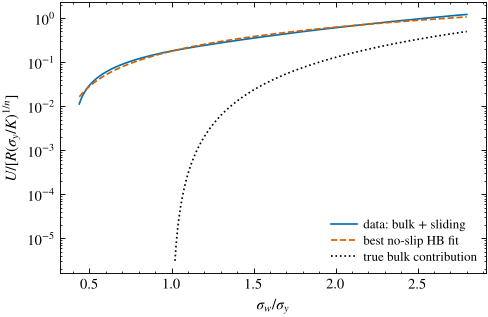

In [5]:
detect = U_tot > 1e-2                                   # points where flow is "detected"
print(f"first detected flow at sigma_w/sigma_y = {tw[detect][0]:.3f}  (bulk yield stress = 1, sliding threshold = {sigma_s})")

def resid(p):
    ty_a, K_a, n_a = p
    model = np.array([q_noslip(t, ty_a, K_a, n_a) for t in tw[detect]]) / np.pi
    return model / U_tot[detect] - 1.0

fit = least_squares(resid, x0=[0.3, 1.0, 0.5], bounds=([0, 1e-3, 0.1], [0.999 * tw[detect][0], 100, 3]))
print(f"no-slip HB fit to the data: sigma_y = {fit.x[0]:.3f}, K = {fit.x[1]:.3f}, n = {fit.x[2]:.3f}"
      f"   (truth: 1, 1, 0.5); rms relative misfit = {100 * np.sqrt(np.mean(fit.fun**2)):.1f} %")

fig, ax = plt.subplots(figsize=(5.0, 3.2))
ax.semilogy(tw[detect], U_tot[detect], color=C["blue"], label="data: bulk + sliding")
ax.semilogy(tw[detect], np.array([q_noslip(t, *fit.x) for t in tw[detect]]) / np.pi, color=C["red"], ls="--",
            label="best no-slip HB fit")
ax.semilogy(tw[tw > 1.02], U_bulk[tw > 1.02], color="k", ls=":", label="true bulk contribution")
ax.set(xlabel=r"$\sigma_w/\sigma_y$", ylabel=r"$U/[R(\sigma_y/K)^{1/n}]$")
ax.legend(fontsize=8.5)
plt.show()

The no-slip fit returns an "apparent yield stress" of about a quarter of the true value — below even the sliding threshold — together with a distorted $K$ and $n$, and an 8 % misfit that is easy to dismiss as noise. In the language of Sec. VI C, these are properties of the material–wall pair, not of the material.

### 3.2 When the wall holds better than the bulk: $\sigma_s>\sigma_y$

If the sliding threshold exceeds the yield stress, the material first yields in the bulk and only later starts to slide.

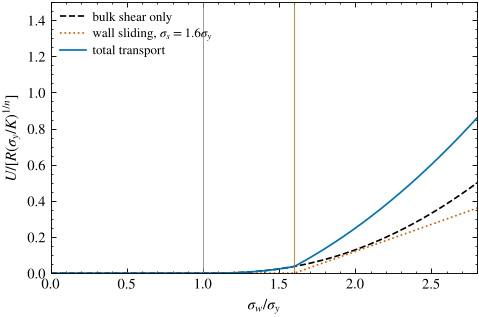

In [6]:
sigma_s_hi = 1.6
U_slip_hi = slip_velocity(tw, Bs, sigma_s_hi, ps)
fig, ax = plt.subplots(figsize=(5.0, 3.2))
ax.plot(tw, U_bulk, color="k", ls="--", label="bulk shear only")
ax.plot(tw, U_slip_hi, color=C["red"], ls=":", label=r"wall sliding, $\sigma_s=1.6\sigma_y$")
ax.plot(tw, U_bulk + U_slip_hi, color=C["blue"], label="total transport")
ax.axvline(sigma_y, color="grey", lw=0.5); ax.axvline(sigma_s_hi, color=C["red"], lw=0.5)
ax.set(xlabel=r"$\sigma_w/\sigma_y$", ylabel=r"$U/[R(\sigma_y/K)^{1/n}]$", xlim=(0, 2.8), ylim=(0, 1.5))
ax.legend(loc="upper left", fontsize=8.5)
plt.show()

Here the onset is the bulk one ($\sigma_w=\sigma_y$) and the near-onset exponent is the bulk value $1+1/n$; sliding only adds a change of slope at $\sigma_s$. In the case $\sigma_s<\sigma_y$, by contrast, the flow rate just above onset grows as $(\sigma_w-\sigma_s)^{p_s}$ — a boundary exponent, not a bulk one (Supplementary Table SIV).

### 3.3 Energy bookkeeping with slip

Supplementary Note S9 E: with wall slip the pressure work per unit length equals the bulk dissipation **plus** the friction work at the wall, $GQ=2\pi\int_0^R(\sigma_y\dot\gamma+K\dot\gamma^{n+1})r\,\mathrm{d}r+2\pi R\sigma_wu_s$. We check this numerically for the Fig. 10(a) parameters.

In [7]:
worst = 0.0
for t in [0.6, 1.3, 2.5]:
    G = 2 * t / R
    gd = lambda r: np.clip((t * r / R - sigma_y) / K, 0, None) ** (1 / n)
    bulk_diss = 2 * np.pi * quad(lambda r: (sigma_y * gd(r) + K * gd(r) ** (n + 1)) * r,
                                 min(sigma_y / t, 1) * R, R, epsabs=0, epsrel=1e-12)[0]
    us = float(slip_velocity(t, Bs, sigma_s, ps))
    wall_work = 2 * np.pi * R * t * us
    Q = q_noslip(t, sigma_y, K, n, R) + np.pi * R**2 * us
    worst = max(worst, abs(G * Q / (bulk_diss + wall_work) - 1))
    print(f"sigma_w = {t}: G*Q = {G * Q:.6f}, bulk dissipation = {bulk_diss:.6f}, wall friction work = {wall_work:.6f}")
assert worst < 1e-9
print("Pressure work = bulk dissipation + wall friction work (Eq. S24 with the slip term).")

sigma_w = 0.6: G*Q = 0.226195, bulk dissipation = 0.000000, wall friction work = 0.226195
sigma_w = 1.3: G*Q = 2.255723, bulk dissipation = 0.050325, wall friction work = 2.205398
sigma_w = 2.5: G*Q = 15.098494, bulk dissipation = 5.202477, wall friction work = 9.896017
Pressure work = bulk dissipation + wall friction work (Eq. S24 with the slip term).


## 4. Separating slip from bulk flow with several radii

*This section goes beyond the review's figures, to illustrate the multi-radius method described in Secs. VI C and VII D.* We generate "measurements" at the same wall stress, $\sigma_w=2\sigma_y$, in tubes of radius $R=1$ and $R=0.5$ (units of a reference radius), for a weak slip law ($\sigma_s=0$, $p_s=1$, $\tilde B_s=0.002$), and plot $Q/(\pi R^3)$ against $1/R$.

In [8]:
tw0 = 2.0
Bs_weak, sigma_s0, ps0 = 0.002, 0.0, 1.0
radii = np.array([1.0, 0.5])
us_true = float(slip_velocity(tw0, Bs_weak, sigma_s0, ps0))
y_exact = np.array([(q_noslip(tw0, sigma_y, K, n, Ri) + np.pi * Ri**2 * us_true) / (np.pi * Ri**3) for Ri in radii])

slope = (y_exact[0] - y_exact[1]) / (1 / radii[0] - 1 / radii[1])        # straight line through two points
print(f"exact data: recovered slip velocity = {slope:.6f}, true = {us_true:.6f}")
print(f"bulk term Q_bulk/(pi R^3) = {q_noslip(tw0, sigma_y, K, n) / np.pi:.4f};"
      f" slip term u_s/R ranges from {us_true:.4f} to {us_true / 0.5:.4f}")
assert np.isclose(slope, us_true, rtol=1e-10)

exact data: recovered slip velocity = 0.004000, true = 0.004000
bulk term Q_bulk/(pi R^3) = 0.1292; slip term u_s/R ranges from 0.0040 to 0.0080


With exact data the method is exact. Now add 2 % random error to each measured flow rate (fixed seed, 2000 repetitions of the experiment):

true u_s = 0.0040;  estimates: mean = 0.0039, standard deviation = 0.0038
fraction of experiments returning a NEGATIVE slip velocity: 15 %


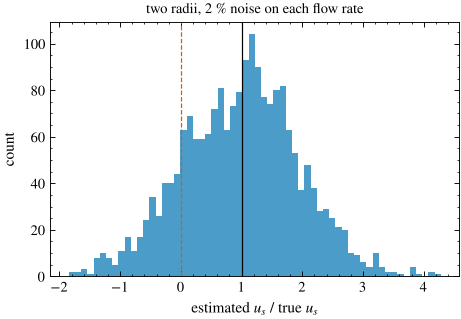

In [9]:
rng = np.random.default_rng(2026)
n_rep = 2000
noisy = y_exact * np.exp(0.02 * rng.standard_normal((n_rep, 2)))
us_est = (noisy[:, 0] - noisy[:, 1]) / (1 / radii[0] - 1 / radii[1])
print(f"true u_s = {us_true:.4f};  estimates: mean = {us_est.mean():.4f}, standard deviation = {us_est.std():.4f}")
print(f"fraction of experiments returning a NEGATIVE slip velocity: {100 * np.mean(us_est < 0):.0f} %")

fig, ax = plt.subplots(figsize=(4.8, 3.0))
ax.hist(us_est / us_true, bins=60, color=C["blue"], alpha=0.7)
ax.axvline(1, color="k", lw=0.8); ax.axvline(0, color=C["red"], lw=0.8, ls="--")
ax.set(xlabel=r"estimated $u_s$ / true $u_s$", ylabel="count", title="two radii, 2 % noise on each flow rate")
ax.title.set_fontsize(9.5)
plt.show()

Because the slip contribution is a small difference between two large numbers, 2 % noise on each flow rate makes the standard deviation of the slip estimate about as large as the slip velocity itself, and a sizeable fraction of experiments return a physically impossible negative slip velocity — exactly the failure the review warns about ("the differences between gaps amplify the noise enough to return negative slip velocities", Sec. VI C). With a single tube, the five or six bulk and slip parameters are rarely identifiable from one pressure–flow curve (Sec. VII D). The reference practice is to measure the slip velocity directly by velocimetry, or to suppress slip with roughened walls and verify the suppression (Sec. VI C).

## 5. A bundle of independent capillaries — Fig. 10(b)

We now drop slip and look at geometry. Following `scripts/fig10_slip_network.py`, five channels with $R/R_{\max}=1,0.8,0.65,0.5,0.35$, $\sigma_y=K=R_{\max}=1$, $n=0.5$; the abscissa is $G/G_{c,\rm widest}$ with $G_{c,\rm widest}=2\sigma_y/R_{\max}$, so channel $i$ has wall stress $\sigma_{w,i}=(G/G_{c,\rm widest})\,R_i\,\sigma_y/R_{\max}$.

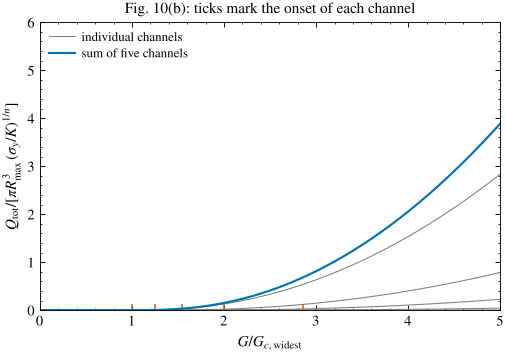

Fig. 10(b): five channel curves, their sum and the onset ticks agree with data/figure_data/fig10_slip_network.csv (rtol 1e-8).


In [10]:
radii_b = [1.0, 0.8, 0.65, 0.5, 0.35]
g = np.linspace(0, 5, 500)                                          # G / G_c,widest
per_channel = {Ri: np.array([q_noslip(v * Ri, sigma_y, K, n, Ri) for v in g]) / np.pi for Ri in radii_b}
total = sum(per_channel.values())

fig, ax = plt.subplots(figsize=(5.4, 3.4))
for k, Ri in enumerate(radii_b):
    ax.plot(g, per_channel[Ri], color=C["grey"], lw=0.7, label="individual channels" if k == 0 else None)
    ax.plot([1 / Ri], [0], marker="|", ms=8, color=C["red"])
    s = stored("(b)", f"channel R/Rmax={Ri:g}")
    assert np.allclose(s.x.to_numpy(), g, rtol=1e-8, atol=1e-12) and np.allclose(s.y.to_numpy(), per_channel[Ri], rtol=1e-8, atol=1e-12)
    tick = stored("(b)", f"onset of channel R/Rmax={Ri:g}").iloc[0]
    assert tick.kind == "markers" and np.isclose(tick.x, 1 / Ri) and tick.y == 0
ax.plot(g, total, color=C["blue"], lw=1.4, label="sum of five channels")
s = stored("(b)", "sum of five channels")
assert np.allclose(s.y.to_numpy(), total, rtol=1e-8, atol=1e-12)
ax.set(xlabel=r"$G/G_{c,\mathrm{widest}}$", ylabel=r"$Q_{\mathrm{tot}}/[\pi R_{\max}^3(\sigma_y/K)^{1/n}]$", ylim=(0, 6), xlim=(0, 5))
ax.legend(loc="upper left", fontsize=8.5)
ax.set_title("Fig. 10(b): ticks mark the onset of each channel", fontsize=10)
plt.show()
print("Fig. 10(b): five channel curves, their sum and the onset ticks agree with "
      "data/figure_data/fig10_slip_network.csv (rtol 1e-8).")

Each channel opens at $G/G_{c,\rm widest}=R_{\max}/R_i$ (ticks at 1, 1.25, 1.54, 2 and 2.86). The total flow starts at the threshold of the widest channel and then rises smoothly. Two consequences for interpreting such data:

* the observed threshold, $G_{c,\rm widest}=2\sigma_y/R_{\max}$, combines the yield stress with the **largest** path size, so the yield stress cannot be extracted from it without knowing $R_{\max}$;
* the curvature of $Q_{\rm tot}(G)$ above onset reflects the recruitment of paths, not only the flow index. The next cell shows how the share of the flow carried by the widest channel changes with $G$, and the local exponent of $Q_{\rm tot}$ against $G-G_{c,\rm widest}$.

G/Gc,widest = 1.50: share of each channel (widest first) = 0.96, 0.04, 0.00, 0.00, 0.00
G/Gc,widest = 2.49: share of each channel (widest first) = 0.81, 0.16, 0.03, 0.00, 0.00
G/Gc,widest = 5.00: share of each channel (widest first) = 0.73, 0.20, 0.06, 0.01, 0.00


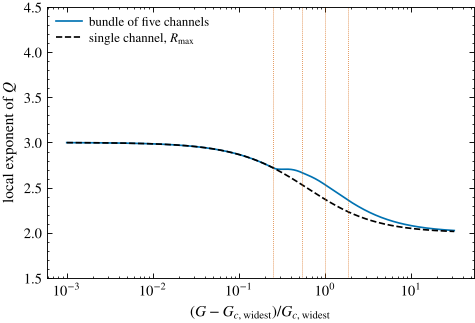

In [11]:
for v in [1.5, 2.5, 5.0]:
    i = np.argmin(abs(g - v))
    shares = ", ".join(f"{per_channel[Ri][i] / total[i]:.2f}" for Ri in radii_b)
    print(f"G/Gc,widest = {g[i]:.2f}: share of each channel (widest first) = {shares}")

# local exponent d ln Q_tot / d ln (G - Gc,widest), compared with a single channel of radius R_max
x = np.logspace(-3, 1.5, 400)                                        # (G - Gc,widest)/Gc,widest
Qb = np.array([sum(q_noslip((1 + v) * Ri, sigma_y, K, n, Ri) for Ri in radii_b) for v in x])
Q1 = np.array([q_noslip(1 + v, sigma_y, K, n, 1.0) for v in x])
fig, ax = plt.subplots(figsize=(5.0, 3.2))
ax.semilogx(x, np.gradient(np.log(Qb), np.log(x)), color=C["blue"], label="bundle of five channels")
ax.semilogx(x, np.gradient(np.log(Q1), np.log(x)), color="k", ls="--", label=r"single channel, $R_{\max}$")
for Ri in radii_b[1:]:
    ax.axvline(1 / Ri - 1, color=C["red"], lw=0.5, ls=":")
ax.set(xlabel=r"$(G-G_{c,\mathrm{widest}})/G_{c,\mathrm{widest}}$", ylabel="local exponent of $Q$", ylim=(1.5, 4.5))
ax.legend(fontsize=8.5)
plt.show()

For the single tube the local exponent falls smoothly from $1+1/n=3$ to $1/n=2$ (Fig. 9(a) of the review). For the bundle, each newly opened channel (dotted lines) holds the exponent above the single-tube curve, producing shoulders instead of a smooth crossover, so the apparent exponent of the network depends on the distribution of path sizes, not just on $n$.

## 6. Why an observed flow threshold is not automatically a bulk yield stress

Pulling together this notebook and the sections of the review it draws on:

* **Wall sliding.** With $\sigma_s<\sigma_y$ the first motion is rigid sliding at $\sigma_w=\sigma_s$ (Sec. VII D, Fig. 10(a)); a no-slip analysis then returns apparent parameters of the material–wall pair (Sec. VI C).
* **Geometry.** In a set of parallel paths the observed threshold is that of the widest path, and the rise above it reflects recruitment of narrower ones (Fig. 10(b); Sec. IX G). Similarly, in a partially sheared Couette gap only part of the sample yields (notebook 04).
* **The controlled variable.** A threshold in imposed force is not a threshold in imposed velocity: a stress-controlled instrument can hold a sample at rest, whereas a speed-controlled one raises the stress until the sample moves (Sec. VII B).
* **Resolution, observation time and history.** A threshold defined by motion below a declared resolution over a declared duration is an engineering quantity (Sec. VI A); gelled materials can need a history-dependent breakaway stress above the steady-flow intercept (Sec. VII B).

**Tests that separate these effects** (Secs. VI C, VI E, VII D): measurements in two or more gaps or tube radii with comparable samples and surfaces; changing the wall texture (smooth versus roughened, with roughness comparable to the particle size); direct velocimetry of the wall velocity (Rheo-PIV, ultrasound, MRI); and reporting the protocol, resolution and controlled variable together with the threshold.

## 7. Try it yourself

**Exercise 1 — slip that grows quadratically.** Meeker, Bonnecaze and Cloitre (2004) found that, below the yield stress, the slip velocity of soft pastes grows as $(\sigma_w/\sigma_y)^2$ (Sec. VI C). Recompute Fig. 10(a) with $\sigma_s=0$, $p_s=2$ and $\tilde B_s=0.1$. Where does flow start, and what share of the transport is sliding at $\sigma_w=1.5\sigma_y$?

*Hint:* reuse `slip_velocity(tw, 0.1, 0.0, 2.0)`. (Note that the review also reports that above $\sigma_y$ the measured slip velocity saturates, which Eq. (27) does not capture.)

<details><summary>Solution</summary>

```python
U_s2 = slip_velocity(tw, 0.1, 0.0, 2.0)
i = np.argmin(abs(tw - 1.5))
print("flow starts at sigma_w = 0+; sliding share at 1.5 sigma_y:", U_s2[i] / (U_bulk[i] + U_s2[i]))   # about 0.91: sliding dominates
```
</details>

**Exercise 2 — three radii instead of two.** Repeat the noisy Mooney experiment of Sec. 4 with radii 1, 0.5 and 0.25 (straight-line fit through three points, `np.polyfit(1/radii, y, 1)`). How often is the slip velocity now negative?

<details><summary>Solution</summary>

```python
radii3 = np.array([1.0, 0.5, 0.25])
y3 = np.array([(q_noslip(tw0, sigma_y, K, n, Ri) + np.pi * Ri**2 * us_true) / (np.pi * Ri**3) for Ri in radii3])
rng3 = np.random.default_rng(7)
est3 = np.array([np.polyfit(1 / radii3, y3 * np.exp(0.02 * rng3.standard_normal(3)), 1)[0] for _ in range(2000)])
print(np.mean(est3 < 0), est3.std() / us_true)   # almost never negative, spread about 1/3 of u_s: a wide range of 1/R helps a lot
```
</details>

**Exercise 3 — a wider path.** Add a sixth channel with $R/R_{\max}=1.25$ (i.e. $R=1.25$ in the units of Fig. 10(b)) to the bundle. Where is the new onset, and by how much does $Q_{\rm tot}$ at $G=2\,G_{c,\rm widest}$ (old definition) increase?

<details><summary>Solution</summary>

```python
radii6 = radii_b + [1.25]
Q6 = sum(q_noslip(2.0 * Ri, sigma_y, K, n, Ri) for Ri in radii6) / np.pi
Q5 = sum(q_noslip(2.0 * Ri, sigma_y, K, n, Ri) for Ri in radii_b) / np.pi
print("new onset at G/Gc,widest(old) =", 1 / 1.25, "; flow ratio at G = 2:", Q6 / Q5, "; share of the new channel:", 1 - Q5 / Q6)
```
The new channel opens at $G = 0.8\,G_{c,\rm widest}$ (old definition), so the observed threshold drops by 20%. At $G = 2\,G_{c,\rm widest}$ the total flow rate increases by a factor of about 5.3, and the single new channel carries about 81% of it: the widest path dominates both the threshold and the flow.
</details>

## Key points

* With wall slip, $Q=Q_{\rm HB,no\text{-}slip}+\pi R^2u_s(\sigma_w)$ (Eq. (26)); with the threshold law, Eq. (27), and $\sigma_s<\sigma_y$ the material slides as a rigid plug for $\sigma_s<\sigma_w<\sigma_y$.
* The first observed motion is at $\min(\sigma_s,\sigma_y)$, and a no-slip HB fit to slipping data returns apparent parameters of the material–wall pair.
* Multi-radius (Mooney/Kalyon) separation is exact in principle but amplifies measurement noise; velocimetry is the reference practice.
* In parallel paths, the widest path sets the threshold and recruitment of narrower paths shapes the curve, so neither the threshold nor the curvature is a material property alone.
* Report the protocol, the controlled variable, the resolution and a slip test with every threshold.

## References

The review and its repository:
* Y. Wang (2026). A century of the Herschel–Bulkley model (1926–2026): Widespread use, community achievements, predictive capability, and engineering implications. Manuscript submitted to the *Journal of Rheology*; code and data: https://github.com/ktwyw/hb-centenary-review

* Mooney, M. (1931). Explicit formulas for slip and fluidity. *Journal of Rheology* **2**, 210–222. https://doi.org/10.1122/1.2116364
* Al-Fariss, T., and Pinder, K. L. (1987). Flow through porous media of a shear-thinning liquid with yield stress. *The Canadian Journal of Chemical Engineering* **65**, 391–405. https://doi.org/10.1002/cjce.5450650306
* Yoshimura, A., and Prud'homme, R. K. (1988). Wall slip corrections for Couette and parallel disk viscometers. *Journal of Rheology* **32**, 53–67. https://doi.org/10.1122/1.549963
* Meeker, S. P., Bonnecaze, R. T., and Cloitre, M. (2004). Slip and flow in soft particle pastes. *Physical Review Letters* **92**, 198302. https://doi.org/10.1103/physrevlett.92.198302
* Kalyon, D. M. (2005). Apparent slip and viscoplasticity of concentrated suspensions. *Journal of Rheology* **49**, 621–640. https://doi.org/10.1122/1.1879043
* Seth, J. R., Cloitre, M., and Bonnecaze, R. T. (2008). Influence of short-range forces on wall-slip in microgel pastes. *Journal of Rheology* **52**, 1241–1268. https://doi.org/10.1122/1.2963135
* Cloitre, M., and Bonnecaze, R. T. (2017). A review on wall slip in high solid dispersions. *Rheologica Acta* **56**, 283–305. https://doi.org/10.1007/s00397-017-1002-7
* Oukhlef, A., Ambari, A., and Champmartin, S. (2020). Identification of the pore size distribution of a porous medium by yield stress fluids using Herschel–Bulkley model. *Mechanics & Industry* **21**, 509. https://doi.org/10.1051/meca/2020032
* Chaparian, E., and Tammisola, O. (2021). Sliding flows of yield-stress fluids. *Journal of Fluid Mechanics* **911**, A17. https://doi.org/10.1017/jfm.2020.1014